Import Libraries and Load Dataset

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

df = pd.read_csv("FakeNewsNet.csv")

df.head()

,title,news_url,source_domain,tweet_num,real
0,Kandi Burruss Explodes Over Rape Accusation on...,http://toofab.com/2017/05/08/real-housewives-a...,toofab.com,42,1
1,People's Choice Awards 2018: The best red carp...,https://www.today.com/style/see-people-s-choic...,www.today.com,0,1
2,Sophia Bush Sends Sweet Birthday Message to 'O...,https://www.etonline.com/news/220806_sophia_bu...,www.etonline.com,63,1
3,Colombian singer Maluma sparks rumours of inap...,https://www.dailymail.co.uk/news/article-33655...,www.dailymail.co.uk,20,1
4,Gossip Girl 10 Years Later: How Upper East Sid...,https://www.zerchoo.com/entertainment/gossip-g...,www.zerchoo.com,38,1


Prepare Dataset

In [16]:
df = df.dropna(subset=['title', 'real'])

df['title'] = df['title'].astype(str)
df['real'] = df['real'].astype(int)

X = df['title']
y = df['real']

print("Total Articles:", len(df))

print("\nClass Distribution:")
print(y.value_counts())

Total Articles: 23196

Class Distribution:
real
1    17441
0     5755
Name: count, dtype: int64


Split Dataset into Training and Testing Sets

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 18556
Testing Samples: 4640


Create Logistic Regression Pipeline        

In [18]:
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words='english',
        max_features=5000
    )),
    ('classifier', LogisticRegression(max_iter=1000))
])

Fine-Tune Hyperparameters Using GridSearchCV

In [19]:
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__l1_ratio': [0],
    'classifier__solver': ['liblinear', 'lbfgs']
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(grid_search.best_score_)

Best Parameters:
{'classifier__C': 10, 'classifier__l1_ratio': 0, 'classifier__solver': 'liblinear'}

Best Cross-Validation Accuracy:
0.8355786385303711


Make Predictions

In [20]:
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print("Predictions:")
print(y_pred[:10])

Predictions:
[1 1 1 1 1 1 1 1 1 0]


Evaluate Model Performance

In [21]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print("Logistic Regression Performance")

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

Logistic Regression Performance
Accuracy: 0.8446
Precision: 0.8755
Recall: 0.9249
F1 Score: 0.8995


Generate Classification Report

In [22]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['Fake News', 'Real News']
))

              precision    recall  f1-score   support

   Fake News       0.73      0.60      0.66      1151
   Real News       0.88      0.92      0.90      3489

    accuracy                           0.84      4640
   macro avg       0.80      0.76      0.78      4640
weighted avg       0.84      0.84      0.84      4640



Confusion Matrix

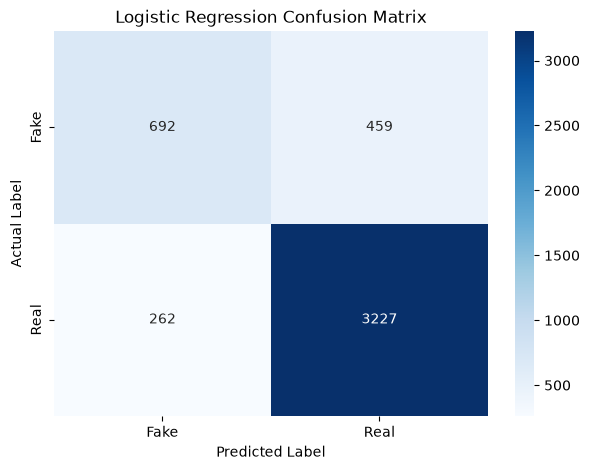

In [23]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fake', 'Real'],
    yticklabels=['Fake', 'Real']
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

Compare Different C Values

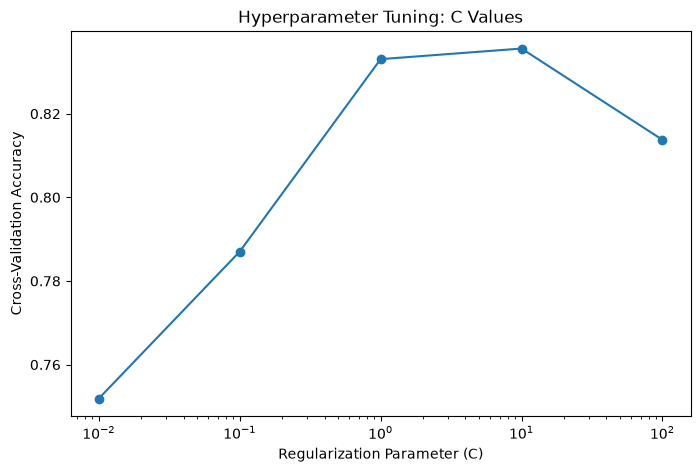

In [24]:
cv_results = pd.DataFrame(grid_search.cv_results_)

c_results = cv_results.groupby(
    'param_classifier__C'
)['mean_test_score'].max()

plt.figure(figsize=(8, 5))

plt.plot(
    c_results.index.astype(float),
    c_results.values,
    marker='o'
)

plt.xscale('log')

plt.title("Hyperparameter Tuning: C Values")
plt.xlabel("Regularization Parameter (C)")
plt.ylabel("Cross-Validation Accuracy")

plt.show()

final results

In [25]:
print("FAKE NEWS CLASSIFICATION RESULTS")

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest CV Accuracy:",
      round(grid_search.best_score_, 4))

print("\nTest Accuracy:", round(accuracy, 4))

print("Precision:", round(precision, 4))

print("Recall:", round(recall, 4))

print("F1 Score:", round(f1, 4))

FAKE NEWS CLASSIFICATION RESULTS

Best Parameters:
{'classifier__C': 10, 'classifier__l1_ratio': 0, 'classifier__solver': 'liblinear'}

Best CV Accuracy: 0.8356

Test Accuracy: 0.8446
Precision: 0.8755
Recall: 0.9249
F1 Score: 0.8995
